# EasyVista Data Challenge: Exploratory Data Analysis of support tickets

**Goal**: for each ticket, predict
- **`sla_violated`**: is the ticket resolved after its SLA deadline? (*classification*)
- **`resolution_time`**: time between opening and resolution, in hours (*regression*)

## Table of contents

1. First look at the data
2. Column types and date conversion
3. Data quality
   - 3.1 Missing values
   - 3.2 Duplicates and abnormal dates
4. Scope: which tickets have an SLA?
5. Building the two targets
6. Target 1: SLA violation
   - 6.1 Violation rate
   - 6.2 How late are the violated tickets?
7. Target 2: resolution time
8. In which unit is `SLA_DELAY` expressed?
9. Variables known when the ticket is opened
   - 9.1 Ticket category
   - 9.2 Urgency
   - 9.3 Impact
   - 9.4 SLA delay
   - 9.5 Request origin
   - 9.6 Are the variables related to each other?
   - 9.7 Is the link statistically solid?
10. Effect of time
    - 10.1 Month by month
    - 10.2 Weekday and opening hour
    - 10.3 At what time are tickets closed?
11. People: requesters and agents
    - 11.1 Concentration
    - 11.2 Does the violation rate depend on the agent?
12. "After the fact" variables: risk of data leakage
    - 12.1 `nb_actions`
    - 12.2 `STATUS_EN`
13. Link between the two targets
14. Summary

## 1. First look at the data

- `pd.read_csv(file, sep=";")` reads the file. The separator is `;`, not `,`.
- `df.shape` gives (number of rows, number of columns).
- `df.head()` shows the first 5 rows.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

df = pd.read_csv("raw_EV_data_challenge.csv", sep=";")
print("Number of rows, columns:", df.shape)
df.head()

Number of rows, columns: (64175, 13)


,REQUEST_ID,SD_CATALOG_PATH_EN,SUBMIT_DATE_UT,URGENCY_VALUE,IMPACT_VALUE,SLA_DELAY,MAX_RESOLUTION_DATE_UT,END_DATE_UT,SUBMITTED_BY_ID,nb_actions,LAST_DONE_BY_ID,STATUS_EN,REQUEST_ORIGIN
0,587385,Incidents,2022-09-22 15:08:53.877,2,3.0,4.0,2022-09-23 10:08:53.000,2022-09-22 15:10:25.000,12826.0,13,12826.0,Active,Front Office
1,587387,Incidents,2022-09-22 15:15:19.267,2,3.0,4.0,2022-09-23 10:15:19.000,2022-09-22 15:16:30.000,12826.0,13,12826.0,Active,Front Office
2,587567,Incidents,2022-09-26 11:29:55.587,2,3.0,4.0,2022-09-26 15:29:55.000,2022-10-27 08:45:27.000,12942.0,15,12942.0,Active,Front Office
3,587665,Incidents,2022-09-27 10:42:02.330,4,3.0,4.0,2022-09-27 14:42:02.000,2022-09-27 10:51:54.000,12172.0,14,12172.0,Active,Front Office
4,587851,Incidents,2022-09-29 10:47:52.850,4,3.0,4.0,2022-09-29 14:47:53.000,2022-09-29 11:00:53.000,13729.0,14,13729.0,Active,Front Office


**Data dictionary** (from the EasyVista presentation)

| Column | Meaning |
|---|---|
| `REQUEST_ID` | Unique ticket identifier |
| `SD_CATALOG_PATH_EN` | Catalog category (Incidents, Service Request, Change, Problem) |
| `SUBMIT_DATE_UT` | Ticket opening date |
| `URGENCY_VALUE` | Urgency: 1 = Critical, 2 = Major, 3 = Minor, 4 = Minor issue, 5 = Service request |
| `IMPACT_VALUE` | Impact: 1 = Critical, 2 = High, 3 = Medium, 4 = Low |
| `SLA_DELAY` | Target SLA delay (in hours) |
| `MAX_RESOLUTION_DATE_UT` | SLA deadline for resolution |
| `END_DATE_UT` | Actual resolution / closing date |
| `SUBMITTED_BY_ID` | User who opened the ticket |
| `nb_actions` | Number of actions recorded on the ticket |
| `LAST_DONE_BY_ID` | User who performed the last action |
| `STATUS_EN` | Status |
| `REQUEST_ORIGIN` | Channel (Front Office = web portal, Email, Phone...) |

## 2. Column types and date conversion

`df.dtypes` shows the type of each column. Dates are read as **text**, so they must be converted.
`pd.to_datetime(..., errors="coerce")` turns text into dates. An unreadable value becomes `NaT` (*Not a Time*, the "empty" value for dates).

In [2]:
print(df.dtypes)

date_cols = ["SUBMIT_DATE_UT", "MAX_RESOLUTION_DATE_UT", "END_DATE_UT"]
for c in date_cols:
    df[c] = pd.to_datetime(df[c], errors="coerce")

print("\nFirst ticket:", df["SUBMIT_DATE_UT"].min())
print("Last ticket :", df["SUBMIT_DATE_UT"].max())

REQUEST_ID                  int64
SD_CATALOG_PATH_EN         object
SUBMIT_DATE_UT             object
URGENCY_VALUE               int64
IMPACT_VALUE              float64
SLA_DELAY                 float64
MAX_RESOLUTION_DATE_UT     object
END_DATE_UT                object
SUBMITTED_BY_ID           float64
nb_actions                  int64
LAST_DONE_BY_ID           float64
STATUS_EN                  object
REQUEST_ORIGIN             object
dtype: object

First ticket: 2022-09-16 06:04:44
Last ticket : 2024-09-16 18:25:36.993000


> **Insights**
>
> - The dataset contains **64,175 tickets** described by **13 columns**, opened between **September 2022 and September 2024** (2 years).
> - `SUBMITTED_BY_ID` and `LAST_DONE_BY_ID` are stored as numbers but are **identifiers**: they must be treated as categories, never as quantities.

## 3. Data quality

### 3.1 Missing values
`df.isna().mean()` = share of empty cells per column (`isna()` is True when the cell is empty, and the mean of True/False gives a proportion).

REQUEST_ID                 0.0
SUBMIT_DATE_UT             0.0
URGENCY_VALUE              0.0
nb_actions                 0.0
IMPACT_VALUE               0.0
SD_CATALOG_PATH_EN         0.0
REQUEST_ORIGIN             1.1
END_DATE_UT                5.0
LAST_DONE_BY_ID            5.5
MAX_RESOLUTION_DATE_UT     6.3
SLA_DELAY                  6.4
STATUS_EN                  9.3
SUBMITTED_BY_ID           14.4
dtype: float64


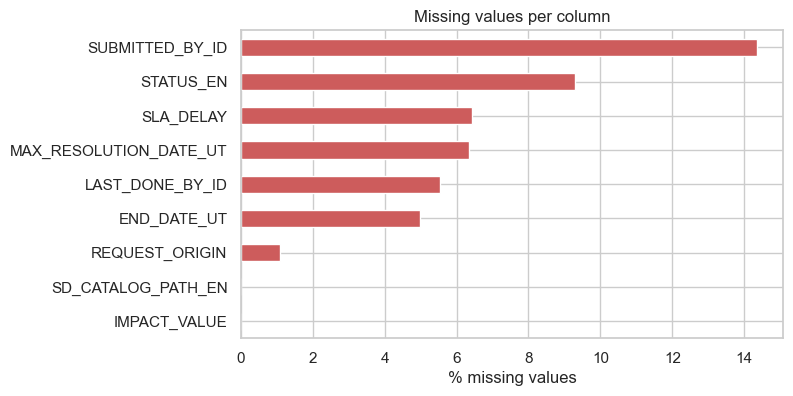

In [3]:
missing = (df.isna().mean() * 100).sort_values()
print(missing.round(1))

missing[missing > 0].plot.barh(color="indianred", figsize=(7, 4))
plt.xlabel("% missing values")
plt.title("Missing values per column")
plt.show()

> **Insights**
>
> - No column is massively empty: the highest rate is **14%** (`SUBMITTED_BY_ID`).
> - `SLA_DELAY` and `MAX_RESOLUTION_DATE_UT` are missing for about **6%** of tickets. These gaps are **not random**: section 4 shows they come from specific categories.
> - `END_DATE_UT` is missing for **5%** of tickets: they were **still open** when the data was extracted.

### 3.2 Duplicates and abnormal dates
- `duplicated()` finds duplicated rows.
- We then look for end dates **before** the opening date, which is impossible.

In [4]:
print("Duplicated rows       :", df.duplicated().sum())
print("Duplicated identifiers:", df["REQUEST_ID"].duplicated().sum())

end_before_start = df[df["END_DATE_UT"] < df["SUBMIT_DATE_UT"]]
print("End before opening    :", len(end_before_start))
print(end_before_start["END_DATE_UT"].value_counts().head())

Duplicated rows       : 0
Duplicated identifiers: 0
End before opening    : 66
END_DATE_UT
1900-01-01 00:00:00.000    65
2024-01-27 00:38:59.043     1
Name: count, dtype: int64


> **Insights**
>
> - There are **no duplicated rows** and no duplicated ticket IDs.
> - About **60 tickets** have an end date on **1 January 1900**. This is a **software default value** meaning "no date", not a real date.
> - Kept as is, it would create durations of **about -1 million hours** and distort every statistic. These dates are therefore **replaced by missing values**.

In [5]:
df.loc[df["END_DATE_UT"] < df["SUBMIT_DATE_UT"], "END_DATE_UT"] = pd.NaT

## 4. Scope: which tickets have an SLA?

We look, **per category**, at the share of tickets without an SLA (`SLA_DELAY` empty).
`groupby("column")` groups rows by value of the column. `agg(...)` then computes a statistic per group.

In [6]:
by_category = df.groupby("SD_CATALOG_PATH_EN").agg(
    n_tickets=("REQUEST_ID", "count"),
    pct_without_SLA=("SLA_DELAY", lambda x: x.isna().mean() * 100),
)
by_category.round(1)

,n_tickets,pct_without_SLA
SD_CATALOG_PATH_EN,,
Change,3664,100.0
Incidents,36407,0.3
Problem,54,98.1
Service Request,24043,1.3


> **Insights**
>
> - **Change** (3,664 tickets) and **Problem** (54 tickets) **almost never have an SLA**: an SLA violation is meaningless for them.
> - They explain almost all the missing SLA values seen in section 3.
> - **Decision**: the analysis and the models focus on **Incidents and Service Requests**.

In [7]:
df = df[df["SD_CATALOG_PATH_EN"].isin(["Incidents", "Service Request"])].copy()
print("Tickets kept:", len(df))

Tickets kept: 60450


## 5. Building the two targets

- **`resolution_time`** = end date minus opening date, in **hours**.
  `.dt.total_seconds()` converts a time difference into seconds, then we divide by 3600.
- **`sla_violated`** = 1 if the end date is **after** the SLA deadline, otherwise 0.

The targets can only be computed for tickets that have an end date **and** a deadline. We store them in `dfc` (*complete df*).

In [8]:
df["resolution_time"] = (df["END_DATE_UT"] - df["SUBMIT_DATE_UT"]).dt.total_seconds() / 3600
df["sla_violated"] = (df["END_DATE_UT"] > df["MAX_RESOLUTION_DATE_UT"]).astype(int)

dfc = df.dropna(subset=["END_DATE_UT", "MAX_RESOLUTION_DATE_UT"]).copy()
print("Tickets with both targets:", len(dfc))
print("Tickets still open       :", df["END_DATE_UT"].isna().sum())

Tickets with both targets: 58997
Tickets still open       : 1186


## 6. Target 1: SLA violation

### 6.1 Violation rate
`value_counts()` counts each value.

Overall violation rate: 24.7%


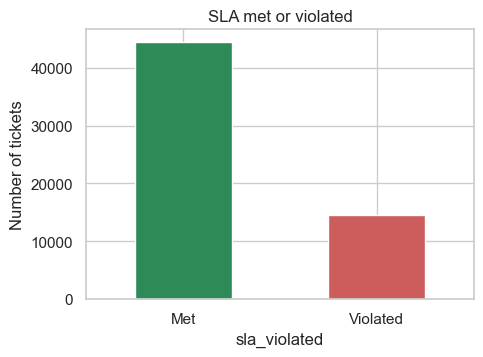

In [9]:
overall_rate = dfc["sla_violated"].mean()
print(f"Overall violation rate: {overall_rate:.1%}")

dfc["sla_violated"].map({0: "Met", 1: "Violated"}).value_counts().plot.bar(
    color=["seagreen", "indianred"], rot=0, figsize=(5, 3.5))
plt.title("SLA met or violated")
plt.ylabel("Number of tickets")
plt.show()

> **Insights**
>
> - **24.7% of tickets violate their SLA**, about **1 in 4**.
> - The classes are **imbalanced** (75% / 25%): a model that always predicts "met" would reach 75% accuracy without learning anything.
> - **Consequence**: evaluate with **recall**, **F1** and **PR-AUC**, not accuracy alone.

### 6.2 How late are the violated tickets?
Delay = end date minus deadline, for violated tickets only.
`describe()` gives the mean, the quartiles and the median (50% quantile).

count    14573.0
mean        26.7
std         50.8
min          0.0
10%          0.2
25%          1.9
50%          8.8
75%         27.2
90%         70.8
max        647.2
Name: delay (days), dtype: float64


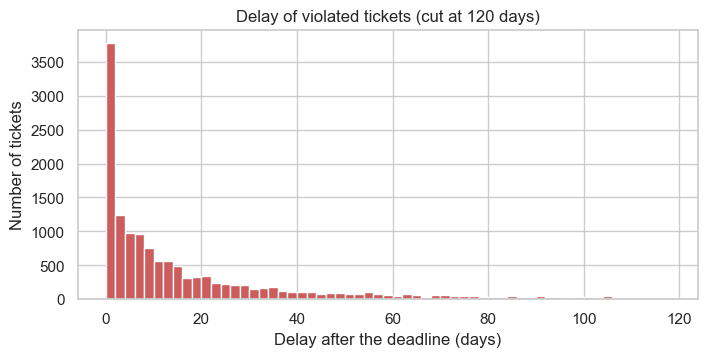

In [10]:
violated = dfc[dfc["sla_violated"] == 1]
delay_h = (violated["END_DATE_UT"] - violated["MAX_RESOLUTION_DATE_UT"]).dt.total_seconds() / 3600
print((delay_h / 24).describe(percentiles=[.1, .25, .5, .75, .9]).round(1).rename("delay (days)"))

plt.figure(figsize=(8, 3.5))
plt.hist(delay_h / 24, bins=np.arange(0, 120, 2), color="indianred")
plt.xlabel("Delay after the deadline (days)")
plt.ylabel("Number of tickets")
plt.title("Delay of violated tickets (cut at 120 days)")
plt.show()

> **Insights**
>
> - Violations are **not small overruns**: the **median delay is about 9 days**, and 1 violation in 4 is **more than a month** late.
> - Two populations appear: tickets handled on time, and tickets that **drift away** far beyond their deadline.
> - **Idea**: besides "violated or not", predicting the **size of the delay** could help prioritise tickets.

## 7. Target 2: resolution time

We compare the **mean** and the **median**. If the mean is much larger, a few very long tickets pull it up: the distribution is **skewed**.
We also plot the **logarithm** of the duration. `np.log10` maps 0.1 h, 1 h, 10 h, 100 h... to equal steps, which makes a very spread distribution readable.

count    58997.0
mean       236.3
std        726.6
min          0.0
10%          0.2
25%          0.9
50%         12.6
75%        145.9
90%        562.6
99%       3523.4
max      15653.0
Name: resolution_time, dtype: float64


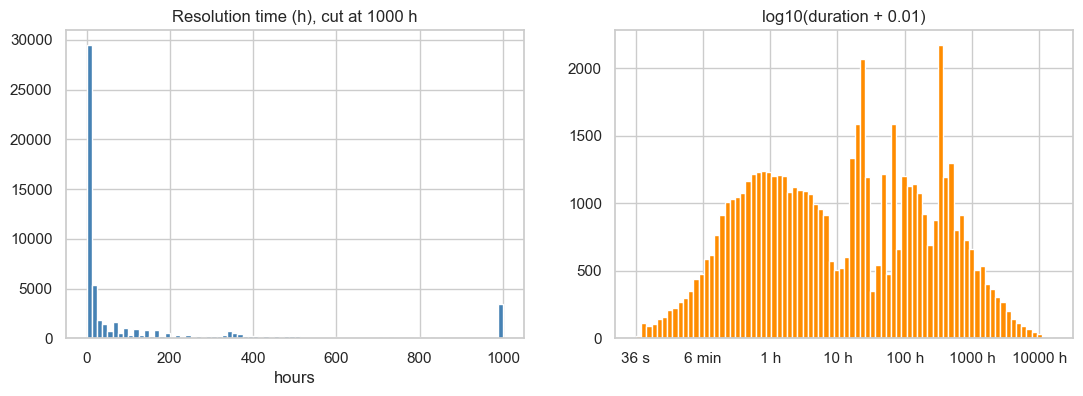

In [11]:
print(dfc["resolution_time"].describe(percentiles=[.1, .25, .5, .75, .9, .99]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(dfc["resolution_time"].clip(upper=1000), bins=80, color="steelblue")
axes[0].set_title("Resolution time (h), cut at 1000 h")
axes[0].set_xlabel("hours")
axes[1].hist(np.log10(dfc["resolution_time"] + 0.01), bins=80, color="darkorange")
axes[1].set_title("log10(duration + 0.01)")
axes[1].set_xticks([-2, -1, 0, 1, 2, 3, 4], ["36 s", "6 min", "1 h", "10 h", "100 h", "1000 h", "10000 h"])
plt.show()

> **Insights**
>
> - The distribution is **highly skewed**: median **about 13 h**, mean **about 236 h**, and 10% of tickets take **more than 23 days**.
> - The log scale reveals **several mechanisms**:
>   - a large bump between a few minutes and a few hours (tickets handled immediately);
>   - peaks around **1 day**, **1 week** and **2 to 3 weeks**: tickets are closed during office hours, so durations cluster on whole days. The 2-3 week peak matches **automatic closures** (section 10.3).
> - **Consequence**: predict the **log of the duration**, and evaluate with **MAE**, which is more robust than RMSE to extreme values.

In [12]:
very_fast = dfc[dfc["resolution_time"] < 0.1]
print(f"Tickets resolved in less than 6 minutes: {len(very_fast)} ({len(very_fast) / len(dfc):.1%})")
print(very_fast["SD_CATALOG_PATH_EN"].value_counts())

Tickets resolved in less than 6 minutes: 3129 (5.3%)
SD_CATALOG_PATH_EN
Service Request    1907
Incidents          1222
Name: count, dtype: int64


> **Insights**
>
> - About **5%** of tickets are closed in **less than 6 minutes**: probably issues **solved on the phone**, **automatic** tickets, or tickets **opened by mistake**.
> - **Question for EasyVista**: are they real tickets, and should they be kept for training?

## 8. In which unit is `SLA_DELAY` expressed?

If `SLA_DELAY` were in **calendar** hours (24 h a day, 7 days a week), we would always have
`deadline - opening date = SLA_DELAY`. We check: for each value of `SLA_DELAY`, we compute the **observed** gap (median).

In [13]:
dfc["allowed_time_h"] = (dfc["MAX_RESOLUTION_DATE_UT"] - dfc["SUBMIT_DATE_UT"]).dt.total_seconds() / 3600

check = dfc.groupby("SLA_DELAY").agg(
    n_tickets=("REQUEST_ID", "count"),
    median_gap_h=("allowed_time_h", "median"),
)
check["median_gap_days"] = check["median_gap_h"] / 24
check.round(1)

,n_tickets,median_gap_h,median_gap_days
SLA_DELAY,,,
1.0,4239,1.0,0.0
4.0,1916,4.0,0.2
8.0,5426,23.0,1.0
9.0,6,24.0,1.0
16.0,110,46.0,1.9
40.0,22383,163.0,6.8
48.0,140,48.0,2.0
80.0,298,269.9,11.2
120.0,18877,120.0,5.0


> **Insights**
>
> - For some SLAs, the deadline matches `SLA_DELAY` in calendar hours (1 h → 1 h, 120 h → 120 h).
> - For others it does not: an **8 h** SLA gives a deadline **about 23 h** later, a **40 h** SLA **about 163 h** later (almost 7 calendar days).
> - This matches **business hours** (about 8 working hours per day, no nights or weekends: 40 business hours = 1 working week).
> - **Consequences**:
>   1. Use **`MAX_RESOLUTION_DATE_UT`** (the real deadline) as the reference, not `SLA_DELAY` alone.
>   2. The **opening day and hour** matter: a ticket opened on Friday evening gets the weekend "for free" (section 10).
>   3. **Question for EasyVista**: which business calendar is used (working hours, public holidays)? Is it the same for every contract?

## 9. Variables known when the ticket is opened

For each variable, we compute per category value:
- the **number of tickets**;
- the **violation rate**;
- the **median resolution time**.

We write a small **function** to avoid repeating the same code 5 times. It displays the table and two charts side by side. The dashed line is the overall average.

In [14]:
def analyze(column, min_tickets=50):
    t = dfc.groupby(column).agg(
        n_tickets=("REQUEST_ID", "count"),
        violation_rate=("sla_violated", "mean"),
        median_duration_h=("resolution_time", "median"),
    )
    t = t[t["n_tickets"] >= min_tickets]
    display(t.round(3))

    fig, axes = plt.subplots(1, 2, figsize=(13, 0.45 * len(t) + 1.5))
    names = t.index.astype(str)
    axes[0].barh(names, t["violation_rate"] * 100, color="indianred")
    axes[0].axvline(overall_rate * 100, ls="--", color="black")
    axes[0].set_title(f"% SLA violated by {column}")
    axes[1].barh(names, t["median_duration_h"], color="steelblue")
    axes[1].axvline(dfc["resolution_time"].median(), ls="--", color="black")
    axes[1].set_title(f"Median duration (h) by {column}")
    for ax in axes:
        ax.invert_yaxis()
    plt.tight_layout()
    plt.show()

### 9.1 Ticket category

,n_tickets,violation_rate,median_duration_h
SD_CATALOG_PATH_EN,,,
Incidents,35609,0.31,23.356
Service Request,23388,0.15,2.557


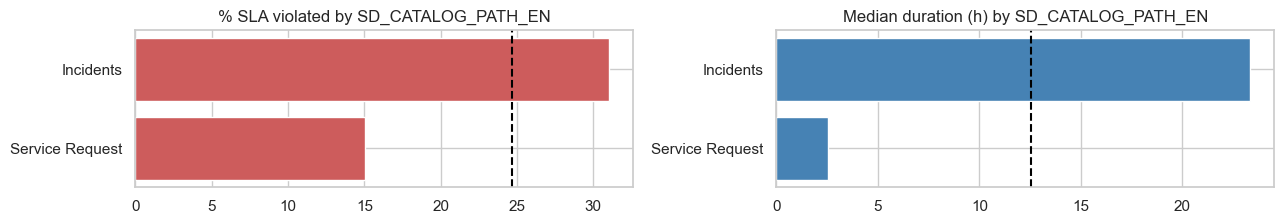

In [15]:
analyze("SD_CATALOG_PATH_EN")

> **Insights**
>
> - **Incidents violate their SLA twice as often as Service Requests** (31% vs 15%).
> - Service Requests are also **much faster** (median about 2.5 h vs about 23 h for Incidents).
> - **The category is a key variable**; a separate model per category is worth testing.

### 9.2 Urgency

,n_tickets,violation_rate,median_duration_h
URGENCY_VALUE,,,
1,2301,0.331,3.323
2,10497,0.322,29.530
3,22998,0.302,22.408
4,2042,0.232,30.257
5,21159,0.143,2.219


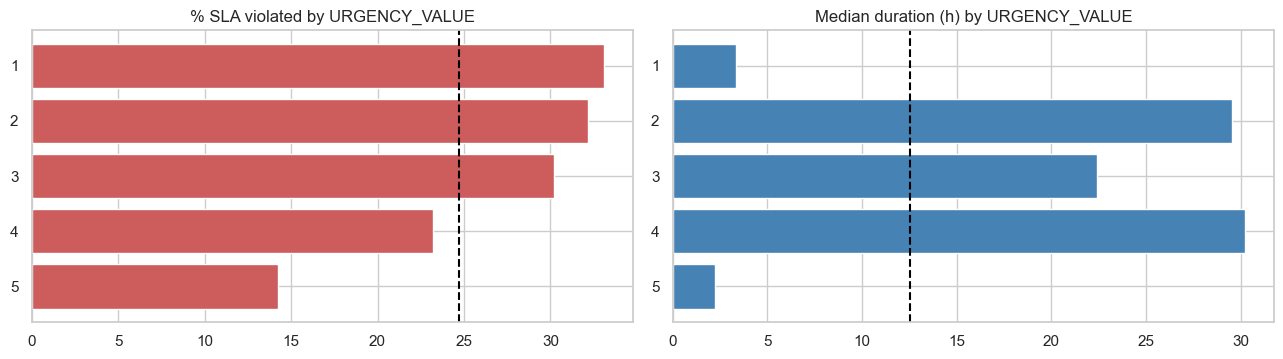

In [16]:
analyze("URGENCY_VALUE")

> **Insights**
>
> - Urgencies **1 to 3** (Critical, Major, Minor) are violated **30 to 33%** of the time, urgency 4 about 23%, urgency 5 (Service request) only **14%**.
> - **Counter-intuitive**: critical tickets are **not** better respected. Their SLA is very short, so it is easier to miss.
> - Urgency 5 is almost only Service Requests: urgency and category are **partly redundant** (section 9.6).

### 9.3 Impact

,n_tickets,violation_rate,median_duration_h
IMPACT_VALUE,,,
1.0,1106,0.283,1.941
2.0,286,0.199,13.119
3.0,54832,0.248,16.384
4.0,2773,0.223,1.110


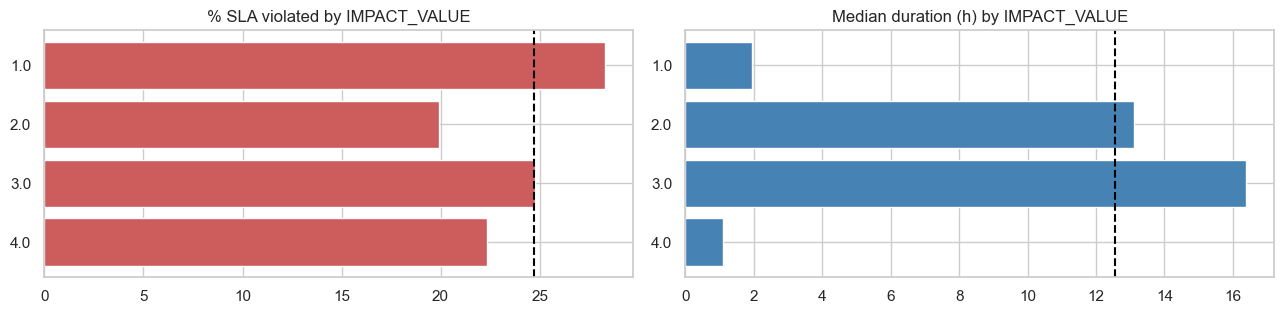

In [17]:
analyze("IMPACT_VALUE")

> **Insights**
>
> - **93%** of tickets have impact **3 (Medium)**: it is almost always left at its **default value**.
> - The variable therefore **carries little information**, despite small differences between the rare categories.

### 9.4 SLA delay

,n_tickets,violation_rate,median_duration_h
SLA_DELAY,,,
1.0,4239,0.372,0.881
4.0,1916,0.186,2.567
8.0,5426,0.406,21.385
16.0,110,0.136,1.435
40.0,22383,0.263,22.106
48.0,140,0.571,80.602
80.0,298,0.178,52.189
120.0,18877,0.190,13.712
135.0,4972,0.160,9.054


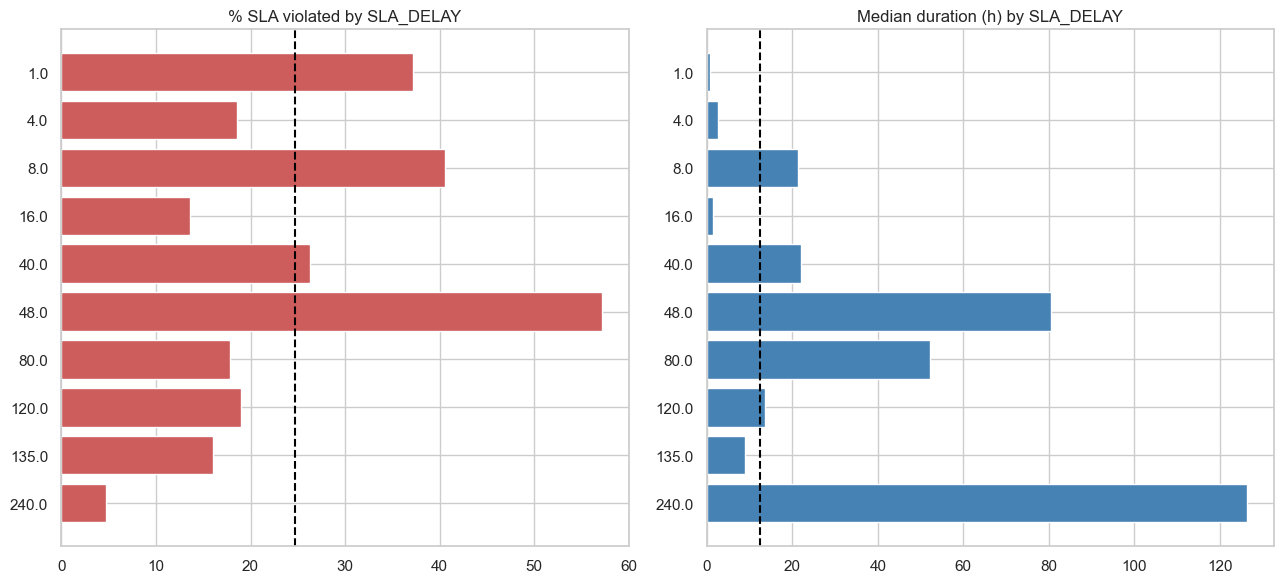

In [18]:
analyze("SLA_DELAY", min_tickets=100)

> **Insights**
>
> - **Short SLAs are violated most often**: 1 h → 37%, 8 h → 41%, 48 h → 57%.
> - **Long SLAs are rarely violated**: 240 h → less than 5%.
> - The allowed time is one of the **best predictors** of violation.

### 9.5 Request origin

,n_tickets,violation_rate,median_duration_h
REQUEST_ORIGIN,,,
Email,8976,0.252,3.363
Front Office,43368,0.248,18.094
Phone,3372,0.232,14.299
Shopping Cart,105,0.229,44.487
Webservice - ES Platform,1564,0.328,23.700
Webservice - EvO Platform,1502,0.122,13.408


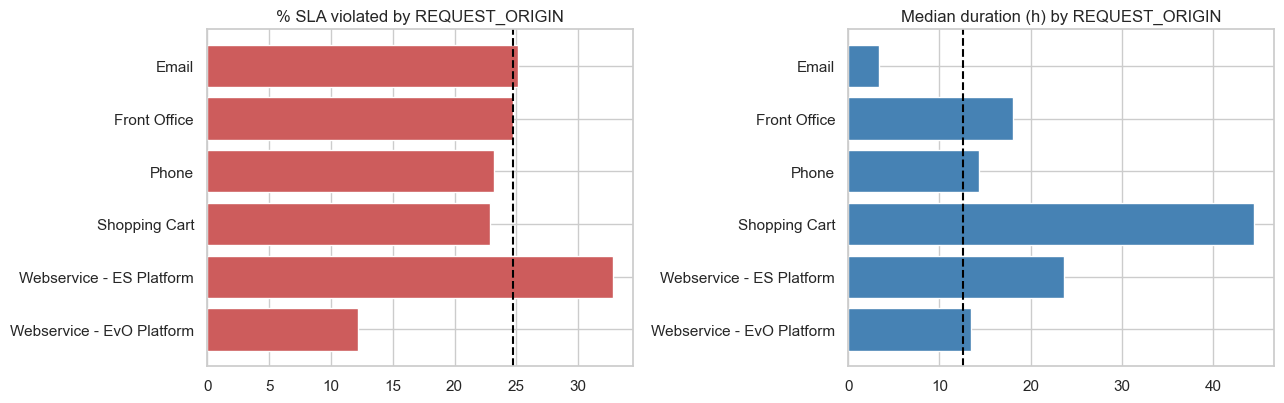

In [19]:
analyze("REQUEST_ORIGIN")

> **Insights**
>
> - The web portal (**Front Office**) brings **almost 75%** of tickets.
> - Differences between channels are moderate, except for the automated platforms: **ES Platform** about **33%** violations, **EvO Platform** about **12%**.
> - Tickets received by **Email** are resolved faster (median about 3 h vs 18 h for Front Office).

### 9.6 Are the variables related to each other?
`pd.crosstab(a, b)` counts tickets for each combination (value of a, value of b). It is a **contingency table**. The heatmap (`sns.heatmap`) colours each cell according to the number of tickets.

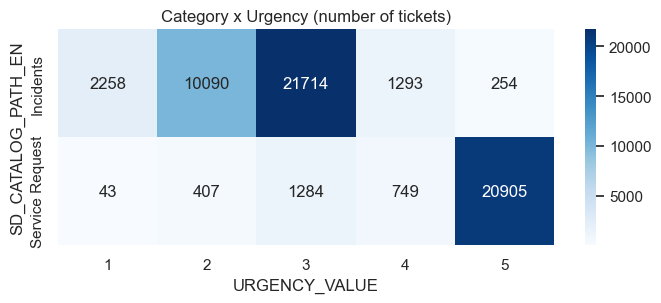

In [20]:
cross = pd.crosstab(dfc["SD_CATALOG_PATH_EN"], dfc["URGENCY_VALUE"])
plt.figure(figsize=(8, 2.8))
sns.heatmap(cross, annot=True, fmt="d", cmap="Blues")
plt.title("Category x Urgency (number of tickets)")
plt.show()

> **Insights**
>
> - Almost all urgency-5 tickets are Service Requests, and almost all Incidents have urgency 1 to 3.
> - Several variables therefore **carry the same information**. This is harmless for tree-based models but must be kept in mind when interpreting linear models.

### 9.7 Is the link statistically solid?
The **chi-squared test** checks whether a variable and the violation are **independent**. A p-value < 0.05 indicates a link that is not due to chance.
With 60,000 tickets, almost everything becomes significant. We therefore also measure the **strength** of the link with **Cramér's V**, between 0 (no link) and 1 (perfect link). Rule of thumb: 0.1 = weak, 0.3 = moderate, 0.5 = strong.

In [21]:
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2, p_value, _, _ = chi2_contingency(table)
    n = table.values.sum()
    k = min(table.shape) - 1
    return np.sqrt(chi2 / (n * k)), p_value

results = {}
for col in ["SD_CATALOG_PATH_EN", "URGENCY_VALUE", "IMPACT_VALUE", "SLA_DELAY", "REQUEST_ORIGIN"]:
    v, p = cramers_v(dfc[col].fillna("empty").astype(str), dfc["sla_violated"])
    results[col] = {"Cramer's V": round(v, 3), "p-value": p}

pd.DataFrame(results).T.sort_values("Cramer's V", ascending=False)

,Cramer's V,p-value
URGENCY_VALUE,0.185,0.000000e+00
SD_CATALOG_PATH_EN,0.181,0.000000e+00
SLA_DELAY,0.180,0.000000e+00
REQUEST_ORIGIN,0.076,1.289819e-69
IMPACT_VALUE,0.018,1.872332e-04


> **Insights**
>
> - The strongest links with violation are **urgency, category and `SLA_DELAY`** (Cramér's V about **0.18**): **real but weak**. Origin (0.08) and impact (0.02) are almost negligible.
> - **No single variable is enough** to predict violation: variables must be **combined**, and **new features created** (opening hour, weekday, requester history...).

## 10. Effect of time

From the opening date we extract:
- `.dt.to_period("M")`: the **month**;
- `.dt.dayofweek`: the **weekday** (0 = Monday, 6 = Sunday);
- `.dt.hour`: the **hour**.

### 10.1 Month by month

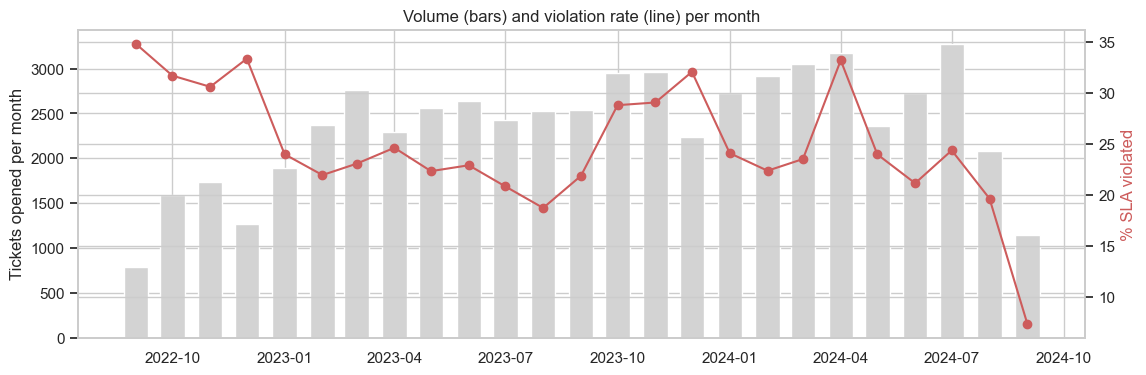

In [22]:
dfc["month"] = dfc["SUBMIT_DATE_UT"].dt.to_period("M").dt.to_timestamp()
monthly = dfc.groupby("month").agg(volume=("REQUEST_ID", "count"), rate=("sla_violated", "mean"))

fig, ax1 = plt.subplots(figsize=(13, 4))
ax1.bar(monthly.index, monthly["volume"], width=20, color="lightgray")
ax1.set_ylabel("Tickets opened per month")
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["rate"] * 100, color="indianred", marker="o")
ax2.set_ylabel("% SLA violated", color="indianred")
plt.title("Volume (bars) and violation rate (line) per month")
plt.show()

> **Insights**
>
> - The violation rate is **not stable over time** (**drift**):
>   - **31-35%** at the end of 2022;
>   - **19-25%** for most of 2023;
>   - **peaks** in October-December 2023 (29-32%) and April 2024 (about 33%), suggesting overload periods or specific events.
> - **Consequence**: split the data **chronologically** (train on the past, test on the most recent months), as in real use.
> - The **last month** (data until 16 September 2024) drops to about **7%**. This is a **censoring bias**: recent long tickets are still open, so they are excluded.
>   The last months are **misleading**: remove them, or use **survival analysis**, which handles unfinished tickets.

### 10.2 Weekday and opening hour

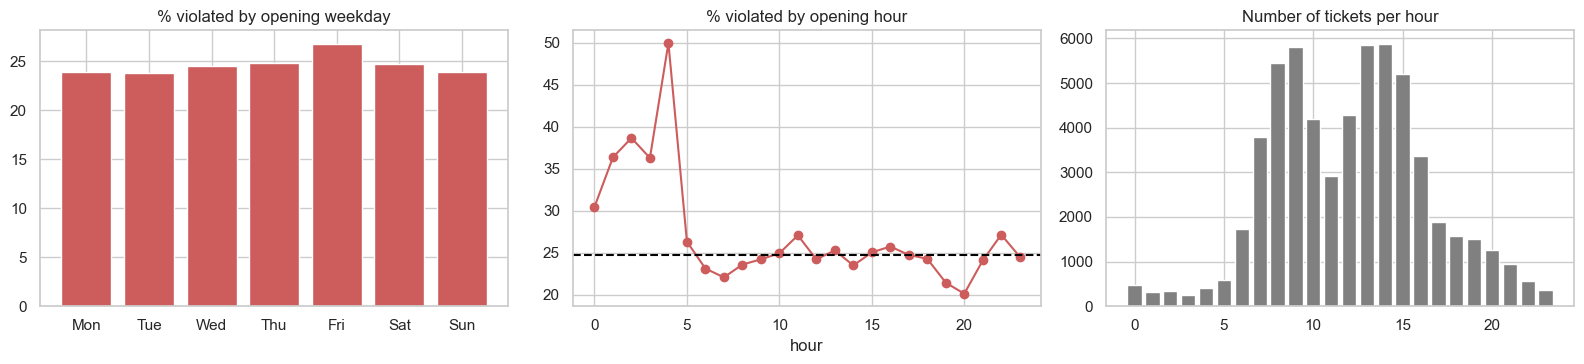

In [23]:
dfc["weekday"] = dfc["SUBMIT_DATE_UT"].dt.dayofweek
dfc["hour"] = dfc["SUBMIT_DATE_UT"].dt.hour
day_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
by_day = dfc.groupby("weekday")["sla_violated"].mean() * 100
axes[0].bar([day_names[d] for d in by_day.index], by_day, color="indianred")
axes[0].set_title("% violated by opening weekday")

by_hour = dfc.groupby("hour")["sla_violated"].mean() * 100
axes[1].plot(by_hour.index, by_hour, marker="o", color="indianred")
axes[1].axhline(overall_rate * 100, ls="--", color="black")
axes[1].set_title("% violated by opening hour")
axes[1].set_xlabel("hour")

axes[2].bar(dfc["hour"].value_counts().sort_index().index, dfc["hour"].value_counts().sort_index(), color="gray")
axes[2].set_title("Number of tickets per hour")
plt.tight_layout()
plt.show()

> **Insights**
>
> - Tickets opened **at night** (midnight to 5 am) violate their SLA **much more often** (30 to 50% depending on the hour, vs about 25% during the day), but they are few (about 1,800).
> - **Friday** is slightly above average (27% vs 24-25%).
> - Volume is concentrated during **office hours**.
> - **Features to create**: opening **hour**, **weekday**, **opened outside business hours** (yes/no).

### 10.3 At what time are tickets **closed**?
Same idea, but with the **end** date (`END_DATE_UT`).

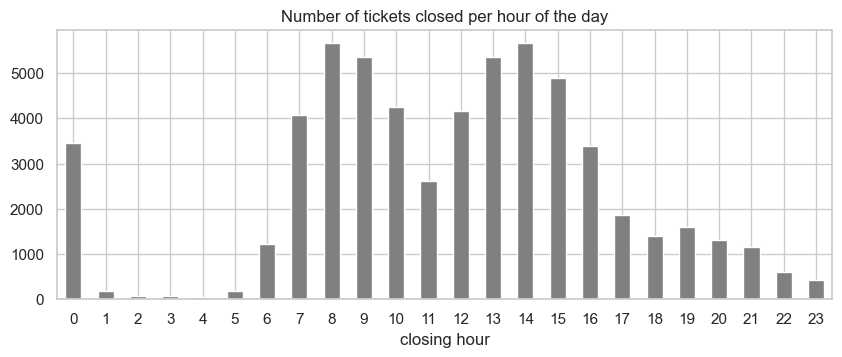

Tickets closed between 0 am and 1 am: 3453 (5.9%)
Violation rate of these tickets      : 50.4%  (others: 23.1%)
Median duration of these tickets     : 17.4 days

Who performs the last action on these tickets?
LAST_DONE_BY_ID
11169.0    0.78
10603.0    0.04
11711.0    0.03
Name: proportion, dtype: float64


In [24]:
dfc["end_hour"] = dfc["END_DATE_UT"].dt.hour
dfc["end_hour"].value_counts().sort_index().plot.bar(color="gray", figsize=(10, 3.5), rot=0)
plt.title("Number of tickets closed per hour of the day")
plt.xlabel("closing hour")
plt.show()

night = dfc[dfc["end_hour"] == 0]
print(f"Tickets closed between 0 am and 1 am: {len(night)} ({len(night) / len(dfc):.1%})")
print(f"Violation rate of these tickets      : {night['sla_violated'].mean():.1%}  (others: {dfc.loc[dfc['end_hour'] != 0, 'sla_violated'].mean():.1%})")
print(f"Median duration of these tickets     : {night['resolution_time'].median() / 24:.1f} days")
print("\nWho performs the last action on these tickets?")
print(night["LAST_DONE_BY_ID"].value_counts(normalize=True).head(3).round(2))

> **Insights**
>
> - **Abnormal peak between midnight and 1 am**: about **3,450 tickets (6%)** are closed at a time when nobody works.
> - **78%** of them (when the agent is known) are closed by the **same account, 11169**: most likely an **automated process**.
> - These tickets last **about 17 days** (median) and are violated **50%** of the time (vs 23% for the others). They represent about **12% of all violations**.
> - **Hypothesis**: the ticket is resolved earlier, then **closed automatically** after a period without user response. `END_DATE_UT` would then be a **closing** date, not a **resolution** date, and part of the violations would be **artificial**.
> - **Priority question for EasyVista**: is `END_DATE_UT` the resolution or the closing date? What is account 11169?

## 11. People: requesters and agents

### 11.1 Concentration
We compute the share of tickets handled by the 10 most frequent people.
`value_counts()` counts tickets per person, already sorted from largest to smallest. `.head(10).sum()` adds up the first 10.

In [25]:
n = len(dfc)
for col in ["SUBMITTED_BY_ID", "LAST_DONE_BY_ID"]:
    counts = dfc[col].value_counts()
    print(f"{col}: {counts.size} different people, "
          f"top 10 = {counts.head(10).sum() / n:.0%} of tickets")

SUBMITTED_BY_ID: 2626 different people, top 10 = 10% of tickets
LAST_DONE_BY_ID: 1217 different people, top 10 = 61% of tickets


> **Insights**
>
> - **Requesters** are very spread out: about **2,600 people**, and the top 10 represent only **10%** of tickets.
> - **Agents** are highly concentrated: **10 people perform the last action on about 60%** of tickets.
> - Account **11169** alone performs the last action on about **22%** of tickets and opens almost all "ES Platform" tickets: it is a **technical (automated) account**, not a person (section 10.3).

### 11.2 Does the violation rate depend on the agent?
We keep agents with at least 200 tickets.

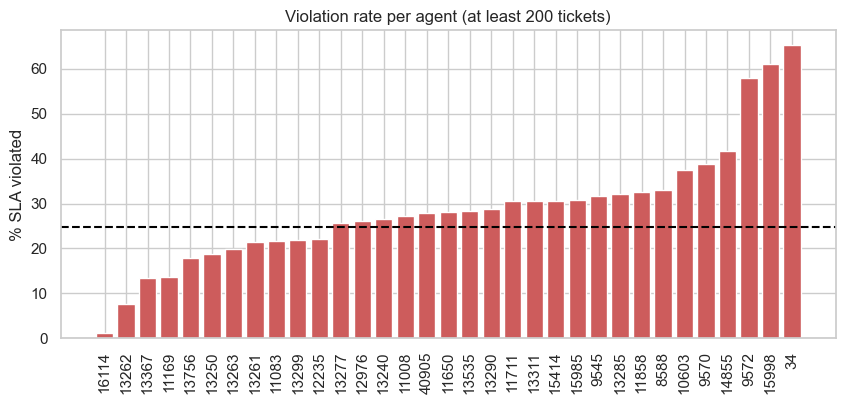

In [26]:
by_agent = dfc.groupby("LAST_DONE_BY_ID").agg(n=("REQUEST_ID", "count"), rate=("sla_violated", "mean"))
by_agent = by_agent[by_agent["n"] >= 200].sort_values("rate")

plt.figure(figsize=(10, 4))
plt.bar(by_agent.index.astype(int).astype(str), by_agent["rate"] * 100, color="indianred")
plt.axhline(overall_rate * 100, ls="--", color="black")
plt.xticks(rotation=90)
plt.ylabel("% SLA violated")
plt.title("Violation rate per agent (at least 200 tickets)")
plt.show()

> **Insights**
>
> - The violation rate varies **enormously** between agents: from **1%** to **more than 60%**.
> - **Warning**: `LAST_DONE_BY_ID` is only known **at the end** of the ticket. Using it to predict would be **data leakage** (section 12).
> - It still shows that **the team handling the ticket matters a lot**. **Question for EasyVista**: is the **assignment group at opening** available?

## 12. "After the fact" variables: risk of data leakage

**Data leakage** happens when a variable is only known **after** the moment we want to predict. The model then looks excellent in testing but is useless in practice.

The natural prediction moment is **when the ticket is opened**. Three columns are problematic.

### 12.1 `nb_actions`
We split `nb_actions` into 5 groups of equal size with `pd.qcut` (**quintiles**), then look at violation and duration in each group.

In [27]:
dfc["actions_group"] = pd.qcut(dfc["nb_actions"], 5)
dfc.groupby("actions_group", observed=True).agg(
    n_tickets=("REQUEST_ID", "count"),
    violation_rate=("sla_violated", "mean"),
    median_duration_h=("resolution_time", "median"),
).round(3)

,n_tickets,violation_rate,median_duration_h
actions_group,,,
"(1.999, 19.0]",12430,0.237,2.131
"(19.0, 24.0]",12006,0.100,2.007
"(24.0, 30.0]",12231,0.172,4.183
"(30.0, 40.0]",11250,0.271,31.545
"(40.0, 865.0]",11080,0.477,196.024


> **Insights**
>
> - The more actions a ticket has, the longer and later it is: above 40 actions, **48% violations** and a median duration of about **8 days**.
> - This is a **consequence, not a cause**: a long ticket accumulates actions. The final number of actions is unknown at opening, so it must be **excluded** from a model that predicts at opening.
> - It becomes useful for a prediction **during the life of the ticket** ("after 5 actions, what is the risk?"). **Question for EasyVista**: when should the prediction be made?

### 12.2 `STATUS_EN`
We cross the status with the presence of an end date.

In [28]:
pd.crosstab(df["STATUS_EN"].fillna("empty"), df["END_DATE_UT"].notna().map({True: "has an end date", False: "no end date"}))

END_DATE_UT,has an end date,no end date
STATUS_EN,,
Active,55548,116
In repair,891,0
Returned,0,3
To Return,0,231
empty,2825,836


> **Insights**
>
> - **92%** of tickets are "**Active**", including tickets that already have an end date, whereas "Active" should mean "open".
> - The other values (*In repair*, *To Return*, *Returned*, *Provisioning*) look like **equipment** statuses, not ticket statuses.
> - This column probably **does not describe the ticket state**, and as a final state it is a **leakage risk**: **exclude it** and clarify with EasyVista.

## 13. Link between the two targets

The challenge suggests a model that predicts **both targets at once**. Let us see how they are related.
In the scatter plot, each point is a ticket: the x axis is the allowed time (`allowed_time_h`), the y axis is the actual duration. Both axes are on a **log scale**.
**Below the diagonal**: resolved on time. **Above**: violated.

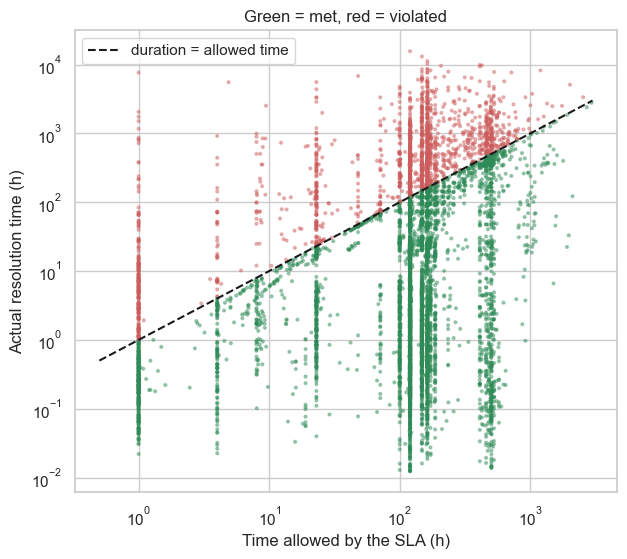

In [29]:
sample = dfc.sample(8000, random_state=0)
colors = sample["sla_violated"].map({0: "seagreen", 1: "indianred"})

plt.figure(figsize=(7, 6))
plt.scatter(sample["allowed_time_h"], sample["resolution_time"] + 0.01, s=4, alpha=0.4, c=colors)
plt.plot([0.5, 3000], [0.5, 3000], "k--", label="duration = allowed time")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("Time allowed by the SLA (h)")
plt.ylabel("Actual resolution time (h)")
plt.title("Green = met, red = violated")
plt.legend()
plt.show()

> **Insights**
>
> - By construction, a ticket is **violated if and only if its duration exceeds the allowed time**: the two targets carry **the same information**.
> - In theory, **one duration model** would be enough (predict the duration, compare it to the deadline). In practice, a few hours of error flips the class.
> - **Good options** for predicting both at once: a **multi-task model** (shared part + two outputs) or a **survival model** (probability that the ticket is still open at time t).

## 14. Summary

### Main insights
1. **64,175 tickets over 2 years**, but **only Incidents and Service Requests have an SLA**. Change and Problem are out of scope.
2. **About 25% violations**, with a median delay of **8 to 9 days** when it happens: violated tickets really drift away.
3. **Highly skewed duration** (median 13 h, mean > 230 h): predict the **log** of the duration.
4. **`SLA_DELAY` is in business hours** for part of the tickets: use `MAX_RESOLUTION_DATE_UT` as the reference.
5. **Best predictors at opening**: SLA delay, category, urgency, opening hour (night is risky). Impact carries little information (93% default value).
6. **Drift over time** and **censoring bias** in the last months: **chronological** train/test split.
7. **Data leakage**: `nb_actions`, `LAST_DONE_BY_ID` and `STATUS_EN` are only known at the end of the ticket and must be excluded from a model "at opening time".
8. **Automatic closures**: about 6% of tickets are closed around midnight by a technical account (11169), with 50% violations. `END_DATE_UT` might be a **closing** date rather than a **resolution** date.
9. **Data quality issues**: end dates on 01/01/1900 (default value); about 5% of tickets closed in less than 6 minutes.

### Implications for modelling
| Topic | Decision |
|---|---|
| Scope | Incidents + Service Requests |
| Regression target | log(duration); evaluate with MAE |
| Classification target | metrics suited to imbalance (F1, PR-AUC) |
| Split | chronological (past to future) |
| Features to create | hour, weekday, outside business hours, actual allowed time, requester history |
| Excluded variables | `nb_actions`, `LAST_DONE_BY_ID`, `STATUS_EN` |
| To test | model with and without the tickets closed automatically at night |
| Baselines | logistic regression + random forest or gradient boosting |

### Questions for EasyVista
1. Is `END_DATE_UT` the **resolution** date or the **closing** date? What does account **11169** do (closures around midnight)?
2. Which **business calendar** is used to compute `MAX_RESOLUTION_DATE_UT`?
3. What exactly does **`STATUS_EN`** describe? Why "Active" on finished tickets?
4. At what **moment** should the prediction be made: at opening, or during processing?
5. Can we get the **initial assignment group** and the **text** (title, description) of the ticket?
6. Are tickets closed in less than 6 minutes real tickets?
7. Is the SLA **paused** when the ticket is waiting for the user?